<a href="https://colab.research.google.com/github/nanditapandey000/Data-Analytics-Project-/blob/main/Week1_Data_Cleaning_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1: Data Gathering, Cleaning and Preprocessing
**Dataset:** African Development Bank Group, Finance-sector projects (`finance1.csv`, source: IATI Data Portal)

**Objective:** take a raw, messy public dataset and turn it into a clean, correctly typed, analysis-ready file, explaining every decision.

**Pipeline in this notebook**
1. Import libraries
2. Upload and load the data
3. Initial exploration
4. Remove structural junk (blank rows, footer)
5. Rename columns and clean text
6. Convert data types
7. Check duplicates and validate values
8. Handle missing values
9. Detect and treat outliers
10. Normalisation / standardisation
11. Feature engineering
12. Final checks, save and download

## Step 1: Import libraries

In [7]:
import pandas as pd                  # data loading and manipulation
import numpy as np                   # numerical operations (log, etc.)
import matplotlib.pyplot as plt      # plotting
from IPython.display import display  # nicer table output

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("Libraries imported successfully")

Libraries imported successfully


## Step 2: Set the data location and load the data
Set `DATA_PATH` below to where your file is. Pick **one** option:

| Where is the file? | What to write |
|---|---|
| Uploaded to Colab (left sidebar, folder icon, Upload) | `"/content/finance1.csv"` |
| In Google Drive (after mounting, see the optional cell) | `"/content/drive/MyDrive/finance1.csv"` |
| On the internet (a direct link) | `"https://.../finance1.csv"` |

**Note on encoding:** this file is *not* UTF-8 (it contains characters such as « » é). Reading it normally gives a `UnicodeDecodeError`, so we explicitly use `cp1252` (Windows-1252).

In [8]:
# ---- CHANGE THIS LINE to the location of your file ----
DATA_PATH = "/content/finance1.csv"
# -------------------------------------------------------

In [9]:
# OPTIONAL: only run this cell if your file is in Google Drive
# from google.colab import drive
# drive.mount("/content/drive")

In [10]:
import os

# Friendly check: stop early with a clear message if the path is wrong
if not DATA_PATH.startswith("http") and not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"File not found: {DATA_PATH}. Upload it via the Colab Files panel "
                            "or correct DATA_PATH in the cell above.")

# Load with the correct encoding
raw = pd.read_csv(DATA_PATH, encoding="cp1252")  # untouched copy kept for before/after comparison
df = raw.copy()                                  # work on a copy
print("Loaded:", DATA_PATH, "| shape:", raw.shape)

Loaded: /content/finance1.csv | shape: (355, 9)


## Step 3: Initial data exploration
Goal: understand structure, types, size and obvious problems **before** changing anything.

In [11]:
print("Shape (rows, columns):", raw.shape)
print("\n--- First 5 rows ---")
display(raw.head())
print("\n--- Last 8 rows (look at the bottom of the file!) ---")
display(raw.tail(8))

Shape (rows, columns): (355, 9)

--- First 5 rows ---


,Project Code,Title,Commitment in U.A,Country,Starting Date,Status,Source of Financing,Sector,Sovereign
0,P-MG-H00-002,Madagascar - Industrialisation and Financial S...,"12,080,000.00",Madagascar,28 Oct 2020,Approved,African Development Fund,Finance,Sovereign
1,P-Z1-H00-063,Multinational - Domestic debt markets developm...,"1,500,000.00",Multinational,13 Oct 2020,Implementation,Fragile States Facility,Finance,Sovereign
2,P-MG-HAZ-001,Madagascar - SME Business Linkages Program,"1,000,000.00",Madagascar,15 May 2020,Implementation,Fragile States Facility,Finance,Sovereign
3,P-MU-H00-004,Mauritius - Stock Exchange Mauritius (SEM) Pro...,"430,000.00",Mauritius,27 Apr 2020,Implementation,Middle Income Countries Fund,Finance,Sovereign
4,P-AO-HAB-009,Angola - Line of Credit to « Banco Millennium ...,"23,415,605.04",Angola,15 Apr 2020,Approved,African Development Bank,Finance,Non Sovereign



--- Last 8 rows (look at the bottom of the file!) ---


,Project Code,Title,Commitment in U.A,Country,Starting Date,Status,Source of Financing,Sector,Sovereign
347,P-TN-HA0-001,1ere Ligne de Crédit à la Banque de développem...,"3,000,000.00",Tunisia,16 Jul 1976,Completion,African Development Bank,Finance,Sovereign
348,P-SL-HA0-001,Line of Credit to Ndb I,"1,000,000.00",Sierra Leone,22 Nov 1974,Completion,African Development Bank,Finance,NaN
349,P-BI-H00-001,Ligne de Crédit,"3,975,264.91",Burundi,21 Nov 1974,Completion,African Development Bank,Finance,Sovereign
350,P-MA-HAA-001,1ère Ligne de Crédit à la Banque Nationale pou...,"3,912,222.92",Morocco,08 May 1974,Completion,African Development Bank,Finance,Sovereign
351,P-MW-HA0-001,Malawi Development Corporation,"1,485,997.20",Malawi,22 Nov 1972,Completion,African Development Bank,Finance,Sovereign
352,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
353,African Development Bank Group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IATI Data Portal
354,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
print("--- Column data types ---")
print(raw.dtypes)
print("\n--- Missing values per column ---")
missing_raw = raw.isna().sum()
print(missing_raw)
print("\nTotal missing cells:", int(missing_raw.sum()))

--- Column data types ---
Project Code           object
Title                  object
Commitment in U.A      object
Country                object
Starting Date          object
Status                 object
Source of Financing    object
Sector                 object
Sovereign              object
dtype: object

--- Missing values per column ---
Project Code           18
Title                  19
Commitment in U.A      19
Country                19
Starting Date          19
Status                 19
Source of Financing    19
Sector                 19
Sovereign              74
dtype: int64

Total missing cells: 225


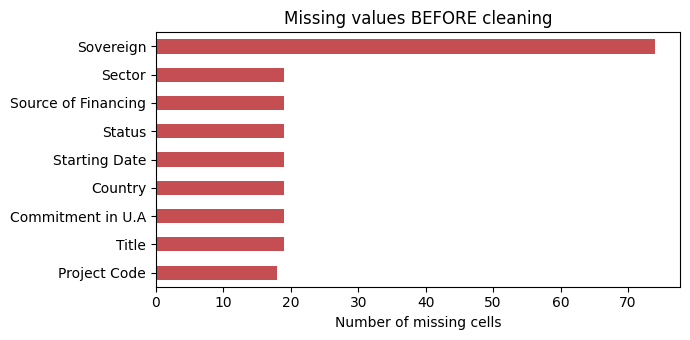

In [13]:
# Visualise missing values in the RAW file
missing_raw[missing_raw > 0].plot(kind="barh", color="#C44E52", figsize=(7, 3.5))
plt.title("Missing values BEFORE cleaning")
plt.xlabel("Number of missing cells")
plt.tight_layout(); plt.show()

In [14]:
# Look at categorical columns to spot inconsistent labels
for col in ["Country", "Status", "Source of Financing", "Sector", "Sovereign"]:
    print(f"\n--- {col} ({raw[col].nunique()} unique) ---")
    print(raw[col].value_counts(dropna=False).head(12))


--- Country (47 unique) ---
Country
Multinational    65
Tunisia          44
Nigeria          29
Morocco          25
NaN              19
Egypt            13
South Africa     12
Kenya            12
Mauritania       11
Rwanda           10
Uganda            9
Zambia            8
Name: count, dtype: int64

--- Status (4 unique) ---
Status
Completion        210
Implementation     95
Approved           26
NaN                19
Cancelled           5
Name: count, dtype: int64

--- Source of Financing (9 unique) ---
Source of Financing
African Development Bank                              224
African Development Fund                               46
Fund for African Private Sector Assistance             27
NaN                                                    19
Middle Income Countries Fund                           16
Fragile States Facility                                11
Global Affairs Canada                                   6
Nigerian Trust Fund                                     4
Mul

### Findings from exploration
- **All columns are text**, including the amount and the date.
- Many rows are **entirely empty** (page-break spacers from the export) and the last row is a **footer**.
- `Sector` has only one value ("Finance"), so it carries no information.
- `Sovereign` has extra missing values.
- Country names are inconsistent (e.g. "Ex Zaire", "Tanzania, United Republic of").

## Step 4: Remove structural junk
Blank spacer rows and the footer ("African Development Bank Group / IATI Data Portal") are **layout artefacts, not projects**, and cannot be imputed, so they are deleted.

In [15]:
n_before = len(df)

blank_rows = df.isna().all(axis=1).sum()      # rows where EVERY column is empty
df = df.dropna(how="all")

footer_rows = df["Title"].isna().sum()        # remaining rows with no title = footer
df = df[df["Title"].notna()].copy()

print(f"Blank rows removed : {blank_rows}")
print(f"Footer rows removed: {footer_rows}")
print(f"Rows: {n_before} -> {len(df)}")

Blank rows removed : 18
Footer rows removed: 1
Rows: 355 -> 336


## Step 5: Rename columns and clean text
- Column names become short `snake_case` (easier to code with).
- Whitespace is trimmed, double spaces collapsed, en-dashes changed to hyphens.
- Country names are standardised (Zaire is the former name of DR Congo).

In [16]:
df.columns = ["project_code", "title", "commitment_ua", "country", "start_date",
              "status", "financing_source", "sector", "sovereign"]

# Strip spaces and collapse repeated spaces in every text column
for col in df.columns:
    df[col] = (df[col].astype(str)
                      .str.strip()
                      .str.replace(r"\s+", " ", regex=True)
                      .replace("nan", np.nan))      # restore real missing values

df["title"] = df["title"].str.replace("\u2013", "-", regex=False)   # en dash -> hyphen

df["country"] = df["country"].replace({
    "Tanzania, United Republic of": "Tanzania",
    "Congo, the Democratic Republic of the": "DR Congo",
    "Ex Zaire": "DR Congo",
})
print("Countries after standardisation:", df["country"].nunique())
display(df.head(3))

Countries after standardisation: 46


,project_code,title,commitment_ua,country,start_date,status,financing_source,sector,sovereign
0,P-MG-H00-002,Madagascar - Industrialisation and Financial S...,"12,080,000.00",Madagascar,28 Oct 2020,Approved,African Development Fund,Finance,Sovereign
1,P-Z1-H00-063,Multinational - Domestic debt markets developm...,"1,500,000.00",Multinational,13 Oct 2020,Implementation,Fragile States Facility,Finance,Sovereign
2,P-MG-HAZ-001,Madagascar - SME Business Linkages Program,"1,000,000.00",Madagascar,15 May 2020,Implementation,Fragile States Facility,Finance,Sovereign


## Step 6: Convert data types
| Column | From | To | Why |
|---|---|---|---|
| `commitment_ua` | text "12,080,000.00" | float | needed for maths |
| `start_date` | text "28 Oct 2020" | datetime | needed for time analysis |
| status, source, sovereign, country | text | category | saves memory, fixed levels |

In [17]:
# Remove thousands separators, then convert. errors="raise" -> would stop if anything is unparsable
df["commitment_ua"] = pd.to_numeric(df["commitment_ua"].str.replace(",", ""), errors="raise")

# Explicit date format avoids day/month confusion
df["start_date"] = pd.to_datetime(df["start_date"], format="%d %b %Y", errors="raise")

for col in ["status", "financing_source", "sector", "sovereign", "country"]:
    df[col] = df[col].astype("category")

print(df.dtypes)
print("\nDate range:", df["start_date"].min().date(), "to", df["start_date"].max().date())

project_code                object
title                       object
commitment_ua              float64
country                   category
start_date          datetime64[ns]
status                    category
financing_source          category
sector                    category
sovereign                 category
dtype: object

Date range: 1972-11-22 to 2020-10-28


## Step 7: Duplicates and validation checks

In [18]:
print("Full-row duplicates      :", df.duplicated().sum())
print("Duplicate project codes  :", df["project_code"].duplicated().sum())
print("Repeated titles          :", df["title"].duplicated().sum())

# Repeated titles with different codes/amounts/dates are DIFFERENT projects -> keep them
display(df[df["title"].duplicated(keep=False)]
        .sort_values("title")[["project_code", "title", "commitment_ua", "start_date"]].head(6))

# Safety net: drop duplicates on the unique key (nothing is removed here)
df = df.drop_duplicates(subset="project_code")

Full-row duplicates      : 0
Duplicate project codes  : 0
Repeated titles          : 16


,project_code,title,commitment_ua,start_date
327,P-TN-HA0-002,3ème Ligne de Crédit à la Banque de développem...,10000000.00,1982-03-16
321,P-TN-HAA-003,3ème Ligne de Crédit à la Banque de développem...,20000000.00,1984-12-12
64,P-KE-HAB-025,Kenya - Commercial Bank of Africa Limited,55997447.49,2017-01-25
63,P-KE-HAB-008,Kenya - Commercial Bank of Africa Limited,35416032.13,2017-01-25
302,P-ZR-HA0-004,Ligne de Crédit Agricole,3987671.82,1987-12-15
304,P-CF-HA0-001,Ligne de Crédit Agricole,639105.85,1987-10-27


In [19]:
# Validation: values must make sense
print("Non-positive amounts :", (df["commitment_ua"] <= 0).sum())
print("Dates in the future  :", (df["start_date"] > pd.Timestamp.today()).sum())

# Project code format: P-XX-XXX-NNN
ok = df["project_code"].str.match(r"^P-[A-Z0-9]{2}-[A-Z0-9]{3}-\d{3}$")
print("Codes not in standard format:", (~ok).sum())
display(df.loc[~ok, ["project_code", "country"]])
print("-> These are legacy/grant IDs (G-..., numeric). They are valid, so they are KEPT.")

Non-positive amounts : 0
Dates in the future  : 0
Codes not in standard format: 7


,project_code,country
49,G-TN-H00-ZZZ-001,Tunisia
144,G-Z1-HZ0-ZZZ-002,Multinational
165,G-Z1-H00-ZZZ-002,Multinational
170,G-Z2-H00-ZZZ-003,Multinational
176,405054,Multinational
184,404791,Multinational
185,404171,South Africa


-> These are legacy/grant IDs (G-..., numeric). They are valid, so they are KEPT.


## Step 8: Handle missing values
After removing layout rows, check what is *really* missing.

In [20]:
print(df.isna().sum())

project_code         0
title                0
commitment_ua        0
country              0
start_date           0
status               0
financing_source     0
sector               0
sovereign           56
dtype: int64


Only `sovereign` has gaps. Options considered:

| Option | Verdict |
|---|---|
| Delete rows | Loses ~17% of projects, rejected |
| Fill with most common value | Would invent information, rejected |
| **Label as "Unknown"** | Keeps all data and is honest, **chosen** |

`sector` is constant ("Finance"), so it is dropped.

In [21]:
df["sovereign"] = df["sovereign"].cat.add_categories("Unknown").fillna("Unknown")
df = df.drop(columns="sector")

print("Missing cells now:", int(df.isna().sum().sum()))
print(df["sovereign"].value_counts())

Missing cells now: 0
sovereign
Sovereign        167
Non Sovereign    113
Unknown           56
Name: count, dtype: int64


## Step 9: Outlier detection and treatment
We use the **IQR rule**: a value is an outlier if it is above Q3 + 1.5 x IQR or below Q1 - 1.5 x IQR.

In [22]:
q1, q3 = df["commitment_ua"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

df["is_outlier_iqr"] = (df["commitment_ua"] < lower) | (df["commitment_ua"] > upper)

print(f"Upper fence: {upper:,.0f} UA")
print(f"Outliers   : {df['is_outlier_iqr'].sum()} ({df['is_outlier_iqr'].mean():.1%})")
print(f"Max amount : {df['commitment_ua'].max():,.0f} UA")
print(f"Skewness   : {df['commitment_ua'].skew():.2f}  (strongly right-skewed)")

Upper fence: 87,619,184 UA
Outliers   : 34 (10.1%)
Max amount : 354,160,321 UA
Skewness   : 2.80  (strongly right-skewed)


**Decision:** these are large but *genuine* credit lines, not data-entry errors, so we **do not delete** them. Instead:
1. **Flag** them (`is_outlier_iqr`)
2. **Log-transform** the amount to reduce skew
3. Create a **winsorized** version (capped at the 99th percentile) for models sensitive to extremes

Skewness after log: -0.37


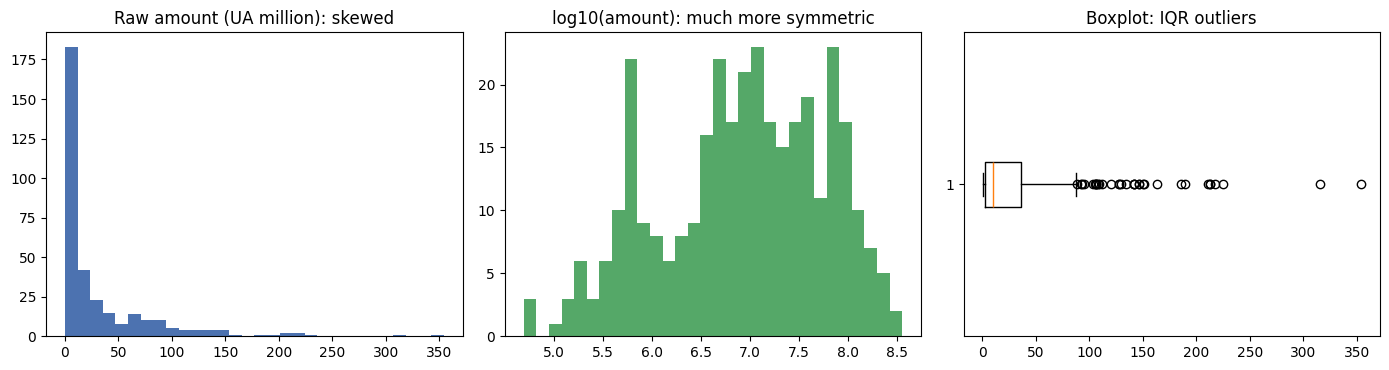

In [23]:
df["log_commitment"] = np.log10(df["commitment_ua"])
df["commitment_winsorized"] = df["commitment_ua"].clip(upper=df["commitment_ua"].quantile(0.99))

print(f"Skewness after log: {df['log_commitment'].skew():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(df["commitment_ua"] / 1e6, bins=30, color="#4C72B0")
ax[0].set_title("Raw amount (UA million): skewed")
ax[1].hist(df["log_commitment"], bins=30, color="#55A868")
ax[1].set_title("log10(amount): much more symmetric")
ax[2].boxplot(df["commitment_ua"] / 1e6, vert=False)
ax[2].set_title("Boxplot: IQR outliers")
plt.tight_layout(); plt.show()

## Step 10: Normalisation and standardisation
- **Min-max scaling** squeezes values to 0-1.
- **Z-score** (applied to the log amount) gives mean 0 and standard deviation 1.

The original column is kept so the file stays interpretable.

In [24]:
amt = df["commitment_ua"]
df["commitment_minmax"] = (amt - amt.min()) / (amt.max() - amt.min())

lg = df["log_commitment"]
df["log_commitment_zscore"] = (lg - lg.mean()) / lg.std()

display(df[["commitment_ua", "commitment_minmax", "log_commitment", "log_commitment_zscore"]].describe().round(3))

,commitment_ua,commitment_minmax,log_commitment,log_commitment_zscore
count,3.360000e+02,336.000,336.000,336.000
mean,3.144820e+07,0.089,6.916,0.000
std,4.987235e+07,0.141,0.843,1.000
min,4.973511e+04,0.000,4.697,-2.633
25%,2.142943e+06,0.006,6.331,-0.694
50%,1.001654e+07,0.028,7.001,0.101
75%,3.633344e+07,0.102,7.560,0.765
max,3.541603e+08,1.000,8.549,1.938


## Step 11: Feature engineering
New columns that will help later exploratory analysis.

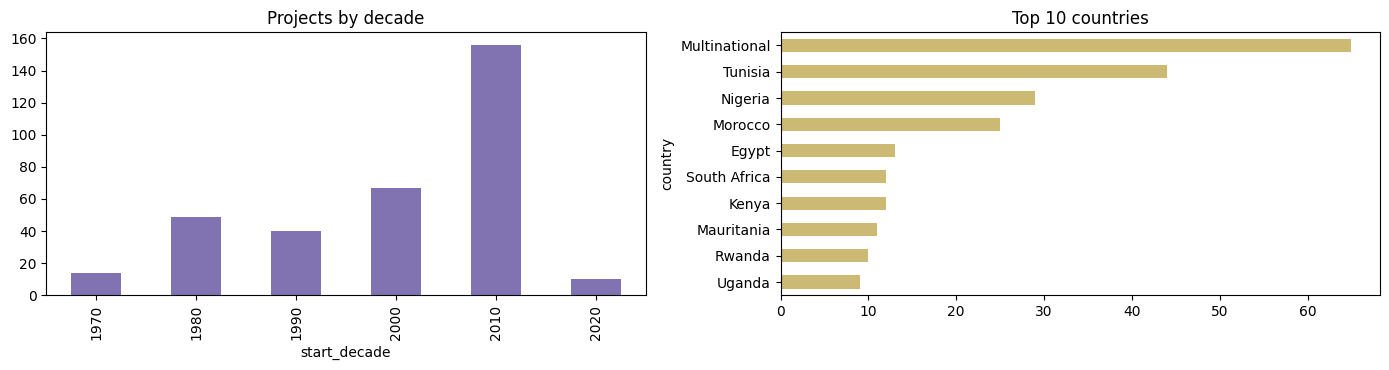

In [25]:
df["start_year"] = df["start_date"].dt.year
df["start_decade"] = (df["start_year"] // 10 * 10).astype(int)
df["is_multinational"] = (df["country"] == "Multinational").astype(int)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
df["start_decade"].value_counts().sort_index().plot.bar(ax=ax[0], color="#8172B2")
ax[0].set_title("Projects by decade")
df["country"].value_counts().head(10).sort_values().plot.barh(ax=ax[1], color="#CCB974")
ax[1].set_title("Top 10 countries")
plt.tight_layout(); plt.show()

## Step 12: Final checks, save and download

In [26]:
df = df.sort_values("start_date", ascending=False).reset_index(drop=True)

print("Final shape:", df.shape)
print("Missing cells:", int(df.isna().sum().sum()))
print("Unique project codes:", df["project_code"].is_unique)
print("\nFinal data types:")
print(df.dtypes)
display(df.head())

Final shape: (336, 16)
Missing cells: 0
Unique project codes: True

Final data types:
project_code                     object
title                            object
commitment_ua                   float64
country                        category
start_date               datetime64[ns]
status                         category
financing_source               category
sovereign                      category
is_outlier_iqr                     bool
log_commitment                  float64
commitment_winsorized           float64
commitment_minmax               float64
log_commitment_zscore           float64
start_year                        int32
start_decade                      int64
is_multinational                  int64
dtype: object


,project_code,title,commitment_ua,country,start_date,status,financing_source,sovereign,is_outlier_iqr,log_commitment,commitment_winsorized,commitment_minmax,log_commitment_zscore,start_year,start_decade,is_multinational
0,P-MG-H00-002,Madagascar - Industrialisation and Financial S...,12080000.00,Madagascar,2020-10-28,Approved,African Development Fund,Sovereign,False,7.082067,12080000.00,0.033973,0.197075,2020,2020,0
1,P-Z1-H00-063,Multinational - Domestic debt markets developm...,1500000.00,Multinational,2020-10-13,Implementation,Fragile States Facility,Sovereign,False,6.176091,1500000.00,0.004096,-0.877967,2020,2020,1
2,P-MG-HAZ-001,Madagascar - SME Business Linkages Program,1000000.00,Madagascar,2020-05-15,Implementation,Fragile States Facility,Sovereign,False,6.000000,1000000.00,0.002684,-1.086919,2020,2020,0
3,P-MU-H00-004,Mauritius - Stock Exchange Mauritius (SEM) Pro...,430000.00,Mauritius,2020-04-27,Implementation,Middle Income Countries Fund,Sovereign,False,5.633468,430000.00,0.001074,-1.521849,2020,2020,0
4,P-AO-HAB-009,Angola - Line of Credit to « Banco Millennium ...,23415605.04,Angola,2020-04-15,Approved,African Development Bank,Non Sovereign,False,7.369505,23415605.04,0.065985,0.538153,2020,2020,0


In [27]:
# Before vs After summary
summary = pd.DataFrame({
    "Raw": [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), "all text"],
    "Cleaned": [df.shape[0], df.shape[1], int(df.isna().sum().sum()), "float / datetime / category / int / bool"],
}, index=["Rows", "Columns", "Missing cells", "Data types"])
display(summary)

,Raw,Cleaned
Rows,355,336
Columns,9,16
Missing cells,225,0
Data types,all text,float / datetime / category / int / bool


In [28]:
# Save as UTF-8 with BOM so accents display correctly in Excel
OUT = "finance_cleaned.csv"
df.to_csv(OUT, index=False, encoding="utf-8-sig")
print("Saved:", OUT)

# Download to your computer (Colab only)
try:
    from google.colab import files
    files.download(OUT)
except ImportError:
    pass

Saved: finance_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
- Removed 19 layout rows (355 to 336 projects), with no real project data lost.
- Fixed encoding, text, country names and data types.
- Kept every project: missing `sovereign` labels became "Unknown" rather than guessed.
- Outliers were documented (flagged, log-transformed, winsorized), not silently deleted.
- Added scaled and engineered columns.
- Result: a clean, validated dataset ready for exploratory analysis and modelling.